# SPP1–CD44 across a whole tissue section — local version of `ScoringVisualization.ipynb`

Three whole-section figures per section, on the R01 deck's dark background:

1. **SPP1–CD44 for every cell** (magma), next to the same map with the **cytotoxic-high** cells in lime on top.
2. **Hotspots:** H&E | SPP1–CD44 where both genes are high | Gi* hotspots of SPP1–CD44 and of granzyme.
3. **The deck figure** (`ScoringVisualization_perSelection`) over the whole section: SPP1–CD44-high cells
   (magma), cytotoxic high (lime) and med (sky blue), and cells that are both (violet).

The magma range and the cytotoxic cuts are **fixed across sections**, so figures from different sections
compare directly. To plot another section, change `TISSUE` and re-run; everything a run writes goes to
`figures/R01_submission/SPP1_CD44_wholeSection/<TISSUE>/`.

Runs locally on kernel **`spatial_cpu_py311`** against the spatial object the spp1Analysis notebooks use
(`data/zarrFiles/1_C2l_annotations_400`: 2,088,557 cells × 19,059 genes, 32 tissues), reading only the
chosen section. Compared with the WSL notebook: the zarr replaces `onefer.h5ad` and the `.gpkg` nuclei
(cell outlines are rounded to look like nuclei), and LIANA scores Spp1→Cd44 only, in real microns.

In [102]:
import warnings; warnings.filterwarnings("ignore")
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import zarr
import shapely
import anndata as ad
import scanpy as sc
import geopandas as gpd
import liana as li
import spatialdata as sd
from anndata.io import read_elem, sparse_dataset
from spatialdata.transformations import get_transformation
from sklearn.neighbors import NearestNeighbors
from scipy.ndimage import gaussian_filter
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Patch
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
from PIL import Image
%matplotlib inline
logging.getLogger("ome_zarr").setLevel(logging.WARNING)   # else it logs every image's metadata on read

In [103]:
# ---- paths: local first; the /coh_labs spellings let the same file run on the cluster ---------
CANDIDATES = [Path("/Users/janzules/Roselab/Spatial/CAR_T"),
              Path("/coh_labs/yunroseli/Jona/CAR-T"),
              Path("/coh_labs/yunroseli/Jona/spatial/CAR-T")]
PROJ = next(p for p in CANDIDATES if p.exists())
_HPC = PROJ.as_posix().startswith("/coh_labs")
# the same object under two directory names (2,088,557 cells x 19,059 genes, 32 tissues)
ZARR_FILE = PROJ / ("data/zarr/fullDataset/processing_Zarr/1_C2l_annotated_CC" if _HPC
                    else "data/zarrFiles/1_C2l_annotations_400")
TABLE = "segmentation_counts"
PATHWAY_CSV = PROJ / "docs/R01_submission/Selected_pathways.csv"    # WSL: .../docs/research/
FIG_ROOT = PROJ / "figures/R01_submission/SPP1_CD44_wholeSection"
# ---- what to draw -------------------------------------------------------------------------------
TISSUE = "RTCyPSCA_1_4"    # <cond>_<loc>_<rep>; in RT arms loc 1 = irradiated, loc 2 = abscopal
FIG_DIR = FIG_ROOT / TISSUE  # every file this run writes goes in a folder named after the section
LIGAND, RECEPTOR = "Spp1", "Cd44"
MODULE_SET = "GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY"
CELL_TYPE_COL = "c2l_consolidated"

# ---- spatial scale ------------------------------------------------------------------------------
# obsm['spatial'] and the polygons are FULL-RES pixels, and 0.34 um is one full-res pixel.
# 02/03/04/06/08 also multiply by the hires scale (~0.20-0.24); doing that here would make cells
# ~2 um wide and ~1.6 um apart. Without it they are ~10 um wide and ~7 um apart, and cell size in
# pixels does not track the hires scale across the 32 tissues -- so the scale is not applied.
UM_PER_PX = 0.34

# ---- LIANA: 04's kernel, in real microns -----------------------------------------------------------
# LR_MAX_NEIGHBOURS caps the neighbourhood: 30 cells reach ~30 um here.
LR_KERNEL, LR_BANDWIDTH_UM, LR_CUTOFF, LR_MAX_NEIGHBOURS = "misty_rbf", 50, 0.1, 30
LR_N_PERMS, LR_NZ_PROP = 100, 0.05
# The raw cosine ignores magnitude: one isolated cell expressing both genes gives every cell around it
# a score near 1. True = in Figures 2-3 and the hotspots, a cell counts as SPP1-CD44 high only where
# both genes are above the section mean around it (liana cats == 1). Figure 1 always shows every cell.
BOTH_HIGH_ONLY = True

# ---- hotspots: the project's Gi* (Spatial_Org_Analysis/Hotspot_Abscopal_Comparison), BH q < HOT_FDR ----
LR_K_GI = 10               # nearest neighbours (+ the cell itself) for SPP1-CD44 hotspots
GZ_K_GI = 10               # ... and for granzyme hotspots
HOT_FDR = 0.05

# ---- fixed across sections, so figures from different sections compare directly ----------------
INT_VMIN, INT_VMAX = 0.0, 0.8   # magma range for the SPP1-CD44 score (0..1) in every figure; above = top colour.
                                # 99th percentile: 0.79 RTCyPSCA_1_4, 0.91 RTCyPSCA_2_4, 0.77 NoTx_2_2
T_CYTO_MED, T_CYTO_HIGH = 0.16, 0.575
                                # granzyme module score cuts = RTCyPSCA_1_4's 70th / 95th percentiles held
                                # fixed. Cells >= high: 5.0% RTCyPSCA_1_4, 6.9% RTCyPSCA_2_4, 0.9% NoTx_2_2;
                                # per-section percentiles would give every section 5% high / 25% med.
PCT_INT = 0.45             # deck rule: INT_HIGH = SPP1-CD44 >= this quantile of the section
SHOW_MED = True            # Figure 3: False = draw cytotoxic-med cells as Other (the deck's "MEDasOTHER")
CYTO_OVER_MAGMA = True     # Figure 1 right panel: lime cells over the magma map; False = over faint grey cells

# ---- look: the deck's scheme (ScoringVisualization_perSelection) ---------------------------------
HE_DARK = dict(alpha=0.80, brightness=0.22, gamma=0.88)    # its "B) Shadow detail" near-black background
HE_GLASS, HE_GLASS_MIN = "#141416", 205                    # bare glass and tears: darkest RGB channel above
                                                           # 205 fades to near-black (fully by 230)
INT_CMAP = "magma"                                         # SPP1-CD44, everywhere
COL_OTHER, ALPHA_OTHER = "#5d6673", 0.30                   # neither signal: grey, mostly see-through
COL_CYTO_MED = "#7dd3fc"                                   # sky blue
COL_CYTO_HIGH = "#a3e635"                                  # lime
COL_BOTH = "#a78bfa"                                       # violet: SPP1-CD44 high AND cytotoxic high
# violet was the candidate that stays apart from magma, lime, sky and grey under protan/deutan
# simulation (dE >= 13.8; cyan collides with sky, white with magma's top)

# ---- cell shape ----------------------------------------------------------------------------------
# The zarr outlines are traced on the 2-um bin grid (staircase edges) and tile the tissue edge to edge.
# Each cell becomes its convex hull, shrunk toward its centre and corner-rounded: nucleus-like blobs
# with dark gaps between them, as in the deck.
ROUND_CELLS = True         # False = the raw segmentation outlines
CELL_SCALE = 0.70          # linear size vs the segmented cell (0.7 -> ~half the area)
CELL_ROUND = 0.65          # corner radius as a fraction of the cell's radius (0 = sharp hull)

# ---- layout -------------------------------------------------------------------------------------
CROP_PAD_PX = 10           # H&E pixels kept around the outermost cells
SCALEBAR_UM = 500
DPI = 300
# Slide copies (*__slide.png): shrunk once, with a proper filter, to fit a 16:9 slide's content area at
# PowerPoint's default 220 ppi -- dragged in, they land at the right size with nothing left to resample
SLIDE_BOX_IN, SLIDE_PPI = (12.5, 6.5), 220

## 1. Load one section

Images and polygons come through the SpatialData API (images stay lazy). The table is read directly
with anndata, and only this tissue's rows, because each tissue is one contiguous block of the 2M-cell
table. Reading the full table would take minutes and ~15 GB for a figure that needs 3% of it.

In [104]:
sdata = sd.read_zarr(ZARR_FILE, selection=("images", "shapes"))
IMG_KEY, SHP_KEY = f"{TISSUE}_hires_tissue_image", f"{TISSUE}_cell_boundaries"
if IMG_KEY not in sdata.images:
    raise KeyError(f"{TISSUE!r} is not in the zarr. Tissues: "
                   f"{sorted(k.removesuffix('_hires_tissue_image') for k in sdata.images)}")
FIG_DIR.mkdir(parents=True, exist_ok=True)   # after the check, so a mistyped TISSUE leaves no empty folder
img_el, cells = sdata.images[IMG_KEY], sdata.shapes[SHP_KEY]
img = np.moveaxis(np.asarray(img_el.values), 0, -1)        # (c, y, x) -> (y, x, c), uint8

# Polygons reach 'downscale_to_hires' by a per-slide scale, the H&E crop by a translation.
# Composing the two puts polygons in H&E pixels.
def to_hires(el):
    return get_transformation(el, "downscale_to_hires").to_affine_matrix(
        input_axes=("x", "y"), output_axes=("x", "y"))

M = np.linalg.inv(to_hires(img_el)) @ to_hires(cells)
UM_PER_IMG_PX = UM_PER_PX / M[0, 0]

# only this tissue's rows of the table
tab = zarr.open_group(ZARR_FILE / "tables" / TABLE, mode="r")
obs_all = read_elem(tab["obs"])
rows = np.flatnonzero(obs_all["tissue"].astype(str).to_numpy() == TISSUE)
lo, hi = int(rows[0]), int(rows[-1]) + 1
assert hi - lo == rows.size, "this tissue's rows are not contiguous; read the full table instead"
adata = ad.AnnData(X=sparse_dataset(tab["X"])[lo:hi],                     # log1p(CP10k)
                   obs=obs_all.iloc[lo:hi].copy(),
                   var=read_elem(tab["var"]),
                   obsm={"spatial": np.asarray(tab["obsm"]["spatial"][lo:hi], dtype=float)})

def round_cells(g, scale, round_frac):
    hull = shapely.convex_hull(g)                                   # drops the bin-grid staircase
    ctr = shapely.get_coordinates(shapely.centroid(hull))
    _, idx = shapely.get_coordinates(hull, return_index=True)
    small = shapely.transform(hull, lambda xy: ctr[idx] + (xy - ctr[idx]) * scale)
    # corner radius scales with the cell, capped by its inscribed circle so thin cells round fully too
    poly = shapely.get_type_id(small) == 3
    inradius = np.zeros(len(small))
    inradius[poly] = shapely.length(shapely.maximum_inscribed_circle(small[poly], tolerance=0.25))
    r = np.minimum(round_frac * np.sqrt(shapely.area(small) / np.pi), 0.95 * inradius)
    out = shapely.buffer(shapely.buffer(small, -r, quad_segs=6), r, quad_segs=6)
    bad = shapely.is_empty(out)                                     # a handful of degenerate hulls
    out[bad] = small[bad]
    return out

# polygons in table order -> rounded -> H&E pixels -> cropped to the section
geoms = np.asarray(cells.geometry.reindex(adata.obs["cell_id"].astype(str)).values)
assert not shapely.is_missing(geoms).any(), "some cells in the table have no polygon"
if ROUND_CELLS:
    geoms = round_cells(geoms, CELL_SCALE, CELL_ROUND)
gdf_sel = gpd.GeoDataFrame(geometry=gpd.GeoSeries(geoms, index=adata.obs_names))
gdf_sel["geometry"] = gdf_sel.geometry.affine_transform(
    [M[0, 0], M[0, 1], M[1, 0], M[1, 1], M[0, 2], M[1, 2]])
bx0, by0, bx1, by1 = gdf_sel.total_bounds
xmin, ymin = max(0, int(bx0) - CROP_PAD_PX), max(0, int(by0) - CROP_PAD_PX)
xmax = min(img.shape[1], int(np.ceil(bx1)) + CROP_PAD_PX)
ymax = min(img.shape[0], int(np.ceil(by1)) + CROP_PAD_PX)
img_crop = img[ymin:ymax, xmin:xmax]
h, w = img_crop.shape[:2]
gdf_sel["geometry"] = gdf_sel.geometry.translate(xoff=-xmin, yoff=-ymin)
del sdata, cells, obs_all, geoms

o = adata.obs.iloc[0]
CONDITION, LOC = str(o["condition"]), str(o["tumor_loc"])
SITE = ({"1": "irradiated tumour (Tu1)", "2": "abscopal tumour (Tu2)"}.get(LOC, f"Tu{LOC}")
        if CONDITION.startswith("RT") else f"Tu{LOC}, no RT")
SECTION_MM = ((bx1 - bx0) * UM_PER_IMG_PX / 1000, (by1 - by0) * UM_PER_IMG_PX / 1000)
print(f"{TISSUE}: {adata.n_obs:,} cells x {adata.n_vars:,} genes | {CONDITION}, {SITE} | TMA {o['TMA']}")
print(f"section {SECTION_MM[0]:.2f} x {SECTION_MM[1]:.2f} mm | H&E crop {w} x {h} px, "
      f"{UM_PER_IMG_PX:.3f} um per H&E pixel | cells "
      + (f"rounded to {CELL_SCALE:.0%} size" if ROUND_CELLS else "as segmented"))

RTCyPSCA_1_4: 69,639 cells x 19,059 genes | RTCyPSCA, irradiated tumour (Tu1) | TMA F07839
section 2.64 x 2.88 mm | H&E crop 1837 x 2001 px, 1.452 um per H&E pixel | cells rounded to 70% size


## 2. Local SPP1–CD44 score (LIANA bivariate)

For each cell *i*, the local cosine is Σⱼ wᵢⱼ·xⱼ·yⱼ / √(Σⱼ wᵢⱼ·xⱼ² · Σⱼ wᵢⱼ·yⱼ²), where x = Spp1,
y = Cd44 (log1p CP10k) and j runs over the cell's ~30 nearest neighbours, including the cell itself.
It runs from 0, meaning no cell nearby co-expresses the pair, to 1, meaning the two genes rise and fall
together across the neighbourhood. It measures **co-expression**, not ligand on one cell meeting
receptor on another. It also ignores magnitude: a single cell expressing both genes in otherwise
silent tissue scores ~1 for every cell around it. On the all-cell map (Figure 1) these show as small
bright discs (~60 µm across) in dark tissue. Figures 2–3 and the hotspots drop them via `BOTH_HIGH_ONLY`.

In [105]:
adata.obsm["spatial_um"] = adata.obsm["spatial"] * UM_PER_PX
li.ut.spatial_neighbors(adata, bandwidth=LR_BANDWIDTH_UM, cutoff=LR_CUTOFF, kernel=LR_KERNEL,
                        set_diag=True, max_neighbours=LR_MAX_NEIGHBOURS, spatial_key="spatial_um")

# Only Spp1->Cd44: a pair's local score does not depend on which other pairs run alongside it, and
# all ~1,500 matched mouseconsensus pairs would cost minutes here for nothing this notebook plots.
# (liana 1.7 has no `inplace=` argument; that is what stopped 04's per-tissue loop.)
lr = li.mt.bivariate(adata, interactions=[(LIGAND, RECEPTOR)],
                     local_name="cosine", global_name="morans", n_perms=LR_N_PERMS,
                     mask_negatives=False, add_categories=True, nz_prop=LR_NZ_PROP,
                     use_raw=False, verbose=False)
PAIR = f"{LIGAND}^{RECEPTOR}"
assert PAIR in lr.var_names and (lr.obs_names == adata.obs_names).all()

def lr_col(m):
    return np.asarray(m[:, lr.var_names.get_loc(PAIR)].todense()).ravel()

adata.obs["lr_score"] = lr_col(lr.X)                             # local cosine, 0..1
adata.obs["lr_pval"] = lr_col(lr.layers["pvals"])                # local permutation p, uncorrected
adata.obs["lr_cat"] = lr_col(lr.layers["cats"]).astype(int)      # 1 both high | -1 one high | 0 both low
GLOBAL = lr.var.loc[PAIR]

# effective neighbourhood radius: the kernel cutoff or the neighbour cap, whichever binds first
KERNEL_R_UM = LR_BANDWIDTH_UM * {"misty_rbf": np.sqrt(np.log(1 / LR_CUTOFF)),
                                 "gaussian": np.sqrt(2 * np.log(1 / LR_CUTOFF)),
                                 "exponential": np.log(1 / LR_CUTOFF),
                                 "linear": 1 - LR_CUTOFF}[LR_KERNEL]
CAP_R_UM = float(np.median(NearestNeighbors(n_neighbors=LR_MAX_NEIGHBOURS)
                           .fit(adata.obsm["spatial_um"]).kneighbors()[0][:, -1]))
NEIGH_R_UM = min(KERNEL_R_UM, CAP_R_UM)

def fmt_p(p):
    return f"< {1 / LR_N_PERMS:g}" if p == 0 else f"= {p:.3g}"

s = adata.obs["lr_score"]
print(f"{LIGAND} detected in {100 * GLOBAL['ligand_props']:.1f}% of cells, "
      f"{RECEPTOR} in {100 * GLOBAL['receptor_props']:.1f}%")
print(f"neighbourhood: {LR_MAX_NEIGHBOURS} cells, ~{NEIGH_R_UM:.0f} um radius ({LR_KERNEL}, bandwidth {LR_BANDWIDTH_UM} um)")
print(f"global bivariate Moran's R = {GLOBAL['morans']:.3f}, p {fmt_p(GLOBAL['morans_pvals'])} "
      f"({LR_N_PERMS} permutations)")
print(f"local score: median {s.median():.2f}, IQR {s.quantile(.25):.2f}-{s.quantile(.75):.2f}, "
      f"99th pct {s.quantile(.99):.2f}; {100 * (s == 0).mean():.0f}% of cells exactly 0; "
      f"{100 * (s > INT_VMAX).mean():.1f}% above the colour cap {INT_VMAX}")
print("neighbourhood categories:", {k: f"{100 * v:.1f}%" for k, v in adata.obs["lr_cat"].map(
    {1: "both high", -1: "one high", 0: "both low"}).value_counts(normalize=True).items()})

Spp1 detected in 49.1% of cells, Cd44 in 17.5%
neighbourhood: 30 cells, ~29 um radius (misty_rbf, bandwidth 50 um)
global bivariate Moran's R = 0.240, p < 0.01 (100 permutations)
local score: median 0.31, IQR 0.00-0.53, 99th pct 0.79; 38% of cells exactly 0; 0.7% above the colour cap 0.8
neighbourhood categories: {'both low': '49.7%', 'both high': '37.6%', 'one high': '12.8%'}


## 3. Granzyme score, the deck categories, and the hotspots

The granzyme module score from the old notebook (`sc.tl.score_genes`, the 13-gene GO set in
`Selected_pathways.csv`). It is computed per section, but its scale holds across sections: the
non-expressing majority sits near −0.05 in all three sections checked. So the cytotoxic cuts are fixed numbers.

| category | rule | drawn as (Figure 3) |
|---|---|---|
| `BOTH` | `INT_HIGH` **and** cytotoxic high | violet |
| `INT_HIGH` | SPP1–CD44 ≥ p45 of the section (and both genes high nearby) | magma, by score |
| `CYTO_HIGH` | granzyme score ≥ `T_CYTO_HIGH` | lime |
| `CYTO_MED` | granzyme score between `T_CYTO_MED` and `T_CYTO_HIGH` | sky blue |
| `OTHER` | neither | grey, 30% opacity |

Earlier rules apply first, so `INT_HIGH` cells with a med granzyme score stay magma, as in the deck.

**Hotspots** (Figure 2) use Getis-Ord Gi* with binary weights over each cell's k nearest neighbours plus
the cell itself. A cell is a hotspot at BH q < `HOT_FDR`. This is the function
`Spatial_Org_Analysis/Hotspot_Abscopal_Comparison` used for the IFN-γ hotspots, there at k = 50.
SPP1–CD44 uses k = `LR_K_GI` on the local score, set to 0 where the genes are not both high nearby.
Without that, the lone-cell discs would become hotspots. Granzyme uses k = `GZ_K_GI` on the module score.

In [106]:
pth = pd.read_csv(PATHWAY_CSV, sep=None, engine="python")
genes = [x.strip() for x in pth.loc[pth["set_name"] == MODULE_SET, "genes"].iloc[0].split(";")]
vmap = {x.lower(): x for x in adata.var_names}
kept = [vmap[x.lower()] for x in genes if x.lower() in vmap]
missing = [x for x in genes if x.lower() not in vmap]
SCORE_COL = f"{MODULE_SET}__score"
sc.tl.score_genes(adata, kept, score_name=SCORE_COL, ctrl_size=50, use_raw=False)
print(f"[{MODULE_SET}] kept={len(kept)}  missing={len(missing)}" + (f"  {missing}" if missing else ""))

vals = adata.obs["lr_score"].to_numpy()
score_all = adata.obs[SCORE_COL].to_numpy()
both_high = adata.obs["lr_cat"].to_numpy() == 1

# ---- the deck categories ----
thr_int = float(np.quantile(vals, PCT_INT))
int_high = (vals >= thr_int) & (vals > 0)        # a zero score is never "high"
if BOTH_HIGH_ONLY:
    int_high &= both_high
cyto_high = score_all >= T_CYTO_HIGH
cyto_med = (score_all >= T_CYTO_MED) & ~cyto_high
adata.obs["cytotoxic_high"] = cyto_high
adata.obs["category"] = np.select([int_high & cyto_high, int_high, cyto_high, cyto_med],
                                  ["BOTH", "INT_HIGH", "CYTO_HIGH", "CYTO_MED"], default="OTHER")
N_HI = int(cyto_high.sum())
N_BOTH = int((int_high & cyto_high).sum())
EXP_BOTH = int_high.mean() * cyto_high.mean() * len(vals)
HI_IN_INT, HI_ELSEWHERE = 100 * cyto_high[int_high].mean(), 100 * cyto_high[~int_high].mean()
LR_UNDER_HI = float(np.median(vals[cyto_high])) if N_HI else np.nan

# ---- hotspots: the project's Gi*, inlined as in Hotspot_Abscopal_Comparison ----
def gi_star(coords_um, values, k):
    n = len(values)
    _, idx = NearestNeighbors(n_neighbors=k + 1).fit(coords_um).kneighbors(coords_um)  # incl. self
    local_sum = values[idx].sum(axis=1)
    xbar, sd, sw = values.mean(), values.std(ddof=0), idx.shape[1]   # binary weights: sum w^2 = sum w
    z = (local_sum - xbar * sw) / (sd * np.sqrt((n * sw - sw**2) / (n - 1)))
    return z, multipletests(norm.sf(z), method="fdr_bh")[1]

lr_for_gi = vals * both_high if BOTH_HIGH_ONLY else vals
adata.obs["lr_GiZ"], adata.obs["lr_qval"] = gi_star(adata.obsm["spatial_um"], lr_for_gi, LR_K_GI)
adata.obs["lr_hotspot"] = (adata.obs["lr_GiZ"] > 0) & (adata.obs["lr_qval"] < HOT_FDR)
adata.obs["gz_GiZ"], adata.obs["gz_qval"] = gi_star(adata.obsm["spatial_um"], score_all, GZ_K_GI)
adata.obs["gz_hotspot"] = (adata.obs["gz_GiZ"] > 0) & (adata.obs["gz_qval"] < HOT_FDR)
lr_hot, gz_hot = adata.obs["lr_hotspot"].to_numpy(), adata.obs["gz_hotspot"].to_numpy()
adata.obs["hotspot"] = np.select([lr_hot & gz_hot, lr_hot, gz_hot], ["BOTH", "SPP1_CD44", "GRANZYME"], "NONE")

# how close do the two kinds of hotspot sit? Distance to the nearest SPP1-CD44 hotspot cell, among
# cells OUTSIDE those hotspots (inside, the distance is 0 by definition and would drag any baseline down)
N_HOT_BOTH = int((lr_hot & gz_hot).sum())
EXP_HOT_BOTH = lr_hot.mean() * gz_hot.mean() * len(lr_hot)
outside = ~lr_hot
if lr_hot.any() and (gz_hot & outside).any():
    d_lr = NearestNeighbors(n_neighbors=1).fit(adata.obsm["spatial_um"][lr_hot]).kneighbors(adata.obsm["spatial_um"])[0][:, 0]
    D_GZ = np.percentile(d_lr[gz_hot & outside], [25, 50, 75])
    D_OUT = float(np.median(d_lr[outside]))
else:
    D_GZ, D_OUT = np.full(3, np.nan), np.nan

gdf_sel = gdf_sel.join(adata.obs[["lr_score", "lr_cat", "category", "hotspot", "cytotoxic_high"]]
                       .rename(columns={"lr_score": "int_val"}))

print(f"Cuts -> INT_HIGH >= {thr_int:.3g} (p{PCT_INT * 100:.0f}{', both genes high nearby' if BOTH_HIGH_ONLY else ''}) | "
      f"cytotoxic med >= {T_CYTO_MED}, high >= {T_CYTO_HIGH} (fixed across sections)")
print("Counts in section ->", adata.obs["category"].value_counts().to_dict())
print(f"cytotoxic high: {N_HI:,} cells = {100 * N_HI / adata.n_obs:.1f}% | SPP1-CD44 score under them: "
      f"median {LR_UNDER_HI:.2f} vs {np.median(vals):.2f} for all cells")
print(f"cytotoxic high is {HI_IN_INT:.1f}% of INT_HIGH cells vs {HI_ELSEWHERE:.1f}% elsewhere | "
      f"BOTH {N_BOTH:,} cells = {N_BOTH / max(EXP_BOTH, 1e-9):.2f}x the {EXP_BOTH:,.0f} expected if independent")
print(f"SPP1-CD44 hotspots (Gi*, k={LR_K_GI}, BH q < {HOT_FDR}): {int(lr_hot.sum()):,} cells = {100 * lr_hot.mean():.1f}%")
print(f"granzyme hotspots  (Gi*, k={GZ_K_GI}, BH q < {HOT_FDR}): {int(gz_hot.sum()):,} cells = {100 * gz_hot.mean():.1f}%")
print(f"in both hotspots: {N_HOT_BOTH:,} cells = {N_HOT_BOTH / max(EXP_HOT_BOTH, 1e-9):.2f}x the "
      f"{EXP_HOT_BOTH:,.0f} expected if independent")
print(f"outside the SPP1-CD44 hotspots, distance to the nearest one: granzyme-hotspot cells median {D_GZ[1]:.0f} um "
      f"(IQR {D_GZ[0]:.0f}-{D_GZ[2]:.0f}) vs {D_OUT:.0f} um for all cells there")

[GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY] kept=12  missing=1  ['Gsdme']
Cuts -> INT_HIGH >= 0.248 (p45, both genes high nearby) | cytotoxic med >= 0.16, high >= 0.575 (fixed across sections)
Counts in section -> {'OTHER': 27614, 'INT_HIGH': 25353, 'CYTO_MED': 13187, 'CYTO_HIGH': 2937, 'BOTH': 548}
cytotoxic high: 3,485 cells = 5.0% | SPP1-CD44 score under them: median 0.19 vs 0.31 for all cells
cytotoxic high is 2.1% of INT_HIGH cells vs 6.7% elsewhere | BOTH 548 cells = 0.42x the 1,296 expected if independent
SPP1-CD44 hotspots (Gi*, k=10, BH q < 0.05): 21,304 cells = 30.6%
granzyme hotspots  (Gi*, k=10, BH q < 0.05): 5,294 cells = 7.6%
in both hotspots: 360 cells = 0.22x the 1,620 expected if independent
outside the SPP1-CD44 hotspots, distance to the nearest one: granzyme-hotspot cells median 78 um (IQR 40-159) vs 219 um for all cells there


## 4. Figure 1 — SPP1–CD44 for every cell, then with the cytotoxic-high cells on top

Every cell in magma on the fixed `INT_VMIN`–`INT_VMAX` scale, with no threshold. On the right, the same
map with the cytotoxic-high cells in lime, wherever they are. Cells are drawn without outlines; at this
scale outlines would cover the cells.

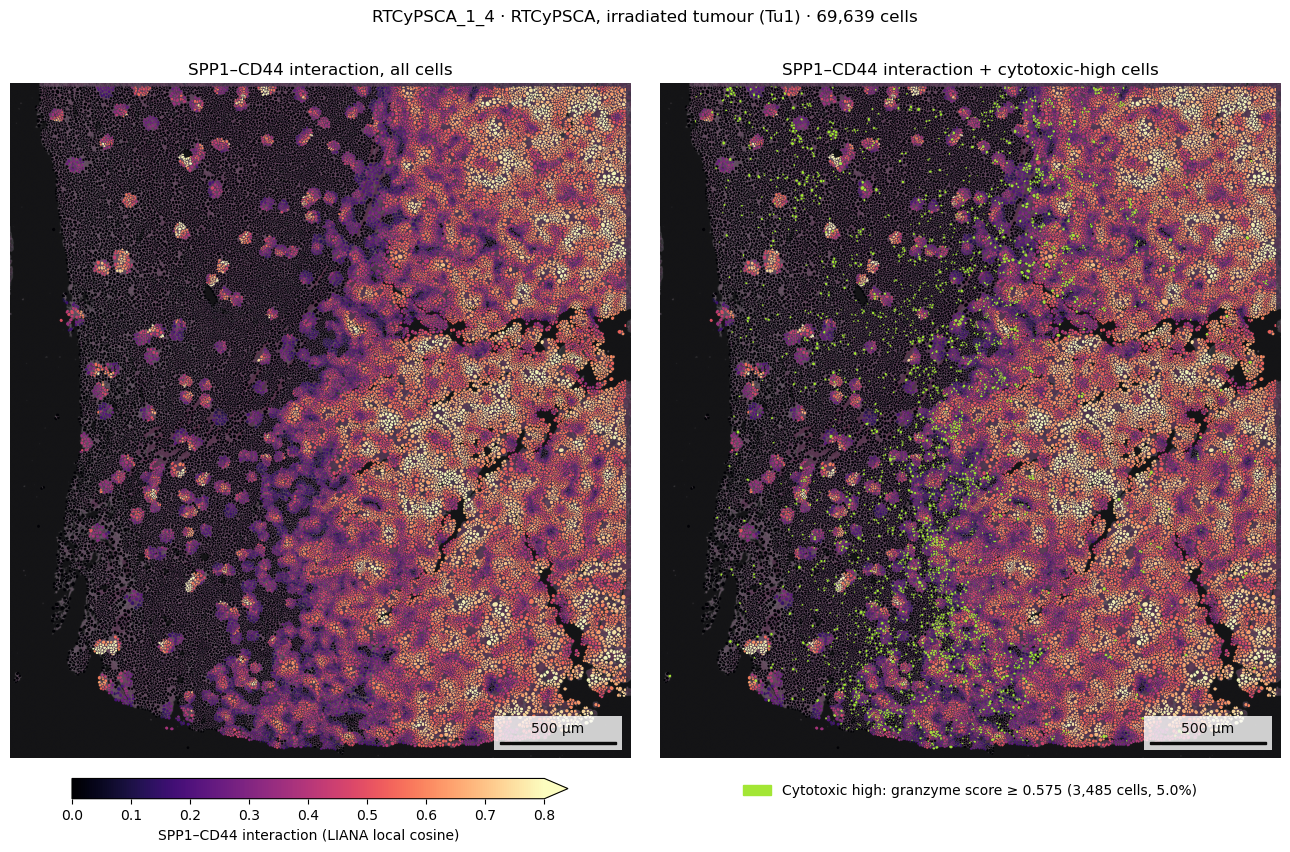

In [107]:
# ---- shared drawing helpers (Figures 1-3) ----
cmap_int = mpl.colormaps[INT_CMAP]
NORM_INT = Normalize(INT_VMIN, INT_VMAX)                 # one magma scale for every figure and section

def magma_colors(g):
    return list(cmap_int(NORM_INT(g["int_val"].to_numpy())))

def panel_fig(ncols, panel_w=5.6, top=0.8, bottom=1.1, gap=0.3, side=0.15):
    # figure sized so every panel has the H&E crop's aspect: no dead space around the maps
    fig_w = ncols * panel_w + (ncols - 1) * gap + 2 * side
    fig_h = panel_w * h / w + top + bottom
    fig, axes = plt.subplots(ncols=ncols, figsize=(fig_w, fig_h))
    fig.subplots_adjust(left=side / fig_w, right=1 - side / fig_w, bottom=bottom / fig_h,
                        top=1 - top / fig_h, wspace=gap / panel_w)
    return fig, axes

def show_he(ax, dark):
    if dark:   # the deck's darkened H&E (its alpha over white, baked in); bare glass near-black, soft-edged
        x = np.clip(img_crop.astype(np.float32) / 255.0 * HE_DARK["brightness"], 0.0, 1.0) ** HE_DARK["gamma"]
        x = HE_DARK["alpha"] * x + (1 - HE_DARK["alpha"])
        glass = gaussian_filter(np.clip((img_crop.min(axis=2).astype(np.float32) - HE_GLASS_MIN) / 25.0, 0.0, 1.0),
                                sigma=1.0)[..., None]
        ax.imshow(x * (1 - glass) + np.asarray(mpl.colors.to_rgb(HE_GLASS)) * glass, extent=(0, w, h, 0))
    else:
        ax.imshow(img_crop, extent=(0, w, h, 0))
    ax.set_xlim(0, w); ax.set_ylim(h, 0)
    ax.set_xticks([]); ax.set_yticks([])
    for sp_ in ax.spines.values():
        sp_.set_visible(False)
    bar = AnchoredSizeBar(ax.transData, SCALEBAR_UM / UM_PER_IMG_PX, f"{SCALEBAR_UM} µm", loc="lower right",
                          frameon=True, color="#0b0b0b", size_vertical=h / 250, label_top=True,
                          sep=4, pad=0.4, borderpad=0.6)
    bar.patch.set(facecolor="white", alpha=0.8, edgecolor="none")
    ax.add_artist(bar)

def int_colorbar(fig, ax, rect, label="SPP1–CD44 interaction (LIANA local cosine)"):
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=NORM_INT, cmap=cmap_int), cax=ax.inset_axes(rect),
                      orientation="horizontal", extend="max")
    cb.set_label(label)
    return cb

def save(fig, stem):
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{stem}.{ext}", dpi=DPI, bbox_inches="tight", pad_inches=0.05)
    im = Image.open(FIG_DIR / f"{stem}.png").convert("RGB")       # slide copy: one Lanczos downsample
    f = min(SLIDE_BOX_IN[0] * SLIDE_PPI / im.width, SLIDE_BOX_IN[1] * SLIDE_PPI / im.height, 1.0)
    im.resize((round(im.width * f), round(im.height * f)), Image.LANCZOS).save(
        FIG_DIR / f"{stem}__slide.png", dpi=(SLIDE_PPI, SLIDE_PPI))
    return stem

TITLE = f"{TISSUE} · {CONDITION}, {SITE} · {adata.n_obs:,} cells"
hi_mask = gdf_sel["cytotoxic_high"].to_numpy()
magma_all = magma_colors(gdf_sel)

fig1, (axL, axR) = panel_fig(2, panel_w=6.2, top=0.85, bottom=1.0)
show_he(axL, dark=True)
gdf_sel.plot(ax=axL, color=magma_all, edgecolor="none", alpha=0.96, rasterized=True)
axL.set_title("SPP1–CD44 interaction, all cells")
int_colorbar(fig1, axL, [0.1, -0.06, 0.8, 0.03])

show_he(axR, dark=True)
if CYTO_OVER_MAGMA:
    gdf_sel.plot(ax=axR, color=magma_all, edgecolor="none", alpha=0.96, rasterized=True)
else:
    gdf_sel[~hi_mask].plot(ax=axR, color=COL_OTHER, edgecolor="none", alpha=ALPHA_OTHER, rasterized=True)
if N_HI:
    gdf_sel[hi_mask].plot(ax=axR, color=COL_CYTO_HIGH, edgecolor="none", zorder=3, rasterized=True)
axR.set_title("SPP1–CD44 interaction + cytotoxic-high cells" if CYTO_OVER_MAGMA else "Cytotoxic-high cells")
axR.legend(handles=[Patch(color=COL_CYTO_HIGH,
                          label=f"Cytotoxic high: granzyme score ≥ {T_CYTO_HIGH} ({N_HI:,} cells, "
                                f"{100 * N_HI / adata.n_obs:.1f}%)")],
           loc="upper center", bbox_to_anchor=(0.5, -0.02), frameon=False)
fig1.suptitle(TITLE, y=1 - 0.12 / fig1.get_figheight(), va="top")
stem1 = save(fig1, f"{TISSUE}__SPP1-CD44_allCells_cytotoxicHigh")
plt.show()

## 5. Figure 2 — hotspots

Left: H&E. Middle: SPP1–CD44 in magma where both genes are high nearby; other cells faint grey while
`BOTH_HIGH_ONLY` is on. Right: SPP1–CD44 hotspots in magma (by score), granzyme hotspots in lime, cells
in both in violet.

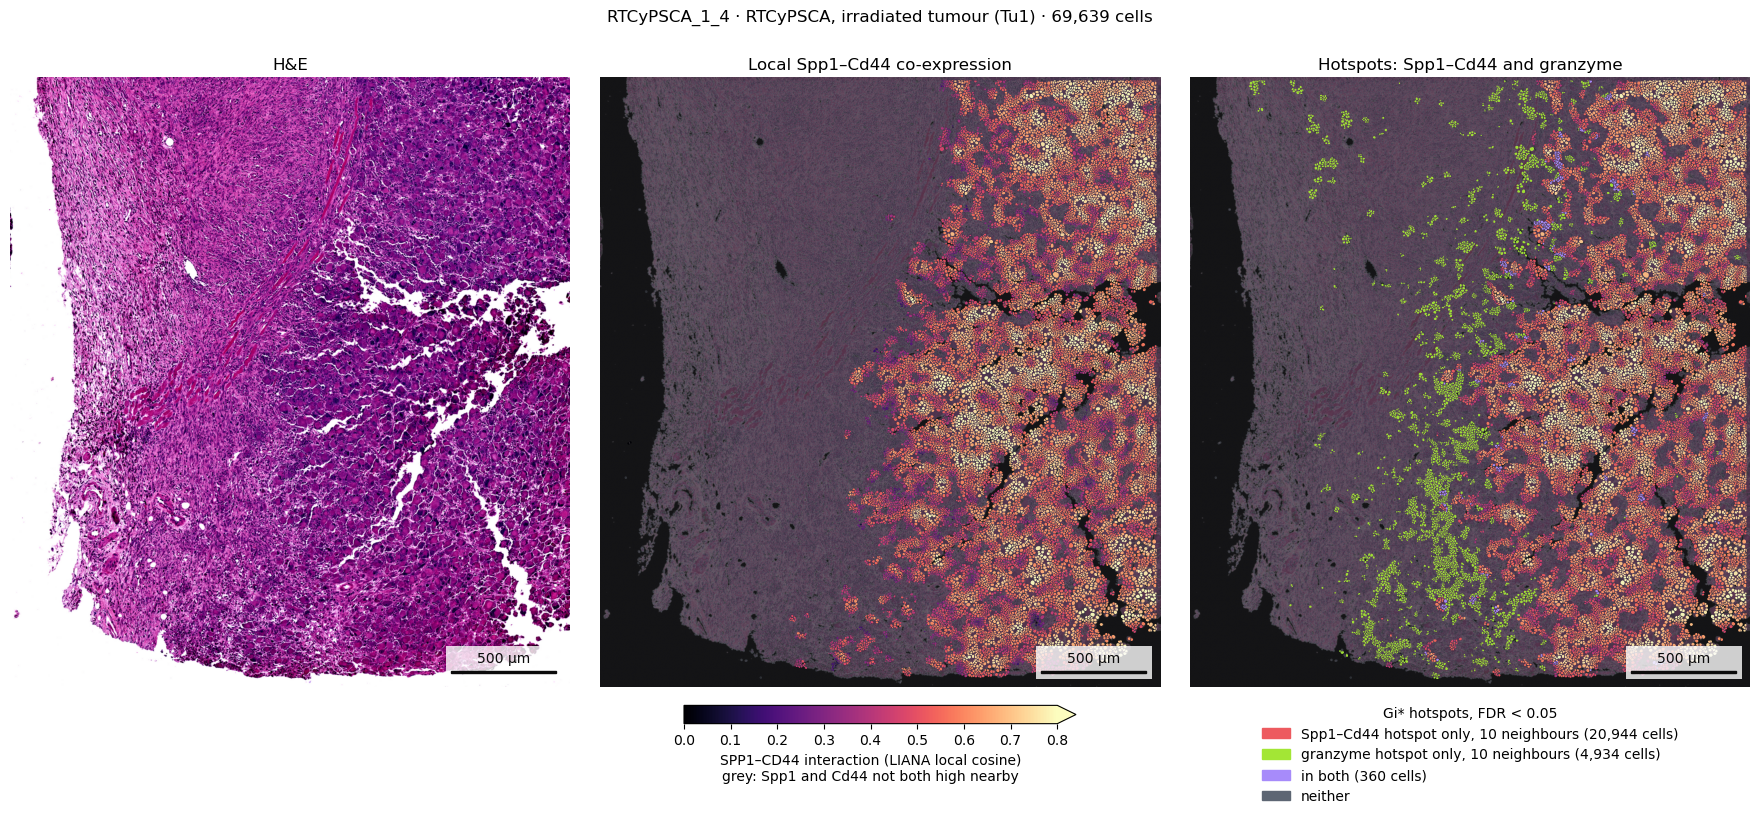

In [108]:
fig2, (axA, axB, axC) = panel_fig(3)
show_he(axA, dark=False)
axA.set_title("H&E")

show_he(axB, dark=True)
shown = (gdf_sel["lr_cat"].to_numpy() == 1) if BOTH_HIGH_ONLY else np.ones(len(gdf_sel), bool)
gdf_sel[~shown].plot(ax=axB, color=COL_OTHER, edgecolor="none", alpha=ALPHA_OTHER, rasterized=True)
gdf_sel[shown].plot(ax=axB, color=magma_colors(gdf_sel[shown]), edgecolor="none", alpha=0.96, rasterized=True)
axB.set_title(f"Local {LIGAND}–{RECEPTOR} co-expression")
int_colorbar(fig2, axB, [0.15, -0.06, 0.7, 0.03],
             label="SPP1–CD44 interaction (LIANA local cosine)"
                   + (f"\ngrey: {LIGAND} and {RECEPTOR} not both high nearby" if BOTH_HIGH_ONLY else ""))

show_he(axC, dark=True)
hs = gdf_sel["hotspot"]
gdf_sel[hs == "NONE"].plot(ax=axC, color=COL_OTHER, edgecolor="none", alpha=ALPHA_OTHER, rasterized=True)
if (hs == "SPP1_CD44").any():
    gdf_sel[hs == "SPP1_CD44"].plot(ax=axC, color=magma_colors(gdf_sel[hs == "SPP1_CD44"]), edgecolor="none",
                                    alpha=0.96, rasterized=True)
if (hs == "GRANZYME").any():
    gdf_sel[hs == "GRANZYME"].plot(ax=axC, color=COL_CYTO_HIGH, edgecolor="none", alpha=0.96, rasterized=True)
if (hs == "BOTH").any():
    gdf_sel[hs == "BOTH"].plot(ax=axC, color=COL_BOTH, edgecolor="none", alpha=0.98, rasterized=True)
axC.set_title(f"Hotspots: {LIGAND}–{RECEPTOR} and granzyme")
n_hs = hs.value_counts()
axC.legend(handles=[Patch(color=cmap_int(0.65), label=f"{LIGAND}–{RECEPTOR} hotspot only, {LR_K_GI} neighbours "
                                                      f"({n_hs.get('SPP1_CD44', 0):,} cells)"),
                    Patch(color=COL_CYTO_HIGH, label=f"granzyme hotspot only, {GZ_K_GI} neighbours "
                                                     f"({n_hs.get('GRANZYME', 0):,} cells)"),
                    Patch(color=COL_BOTH, label=f"in both ({n_hs.get('BOTH', 0):,} cells)"),
                    Patch(color=COL_OTHER, label="neither")],
           loc="upper center", bbox_to_anchor=(0.5, -0.01), frameon=False, title=f"Gi* hotspots, FDR < {HOT_FDR:g}")
fig2.suptitle(TITLE, y=1 - 0.12 / fig2.get_figheight(), va="top")
stem2 = save(fig2, f"{TISSUE}__SPP1-CD44_wholeSection")
plt.show()

## 6. Figure 3 — cytotoxic and SPP1–CD44-interacting cells (the deck figure)

The deck figure (`ScoringVisualization_perSelection`, "Plot 1 - With med categories") over the whole
section, next to the H&E. Polygon edges are off at this scale: outlines on ~70k cells would cover them.

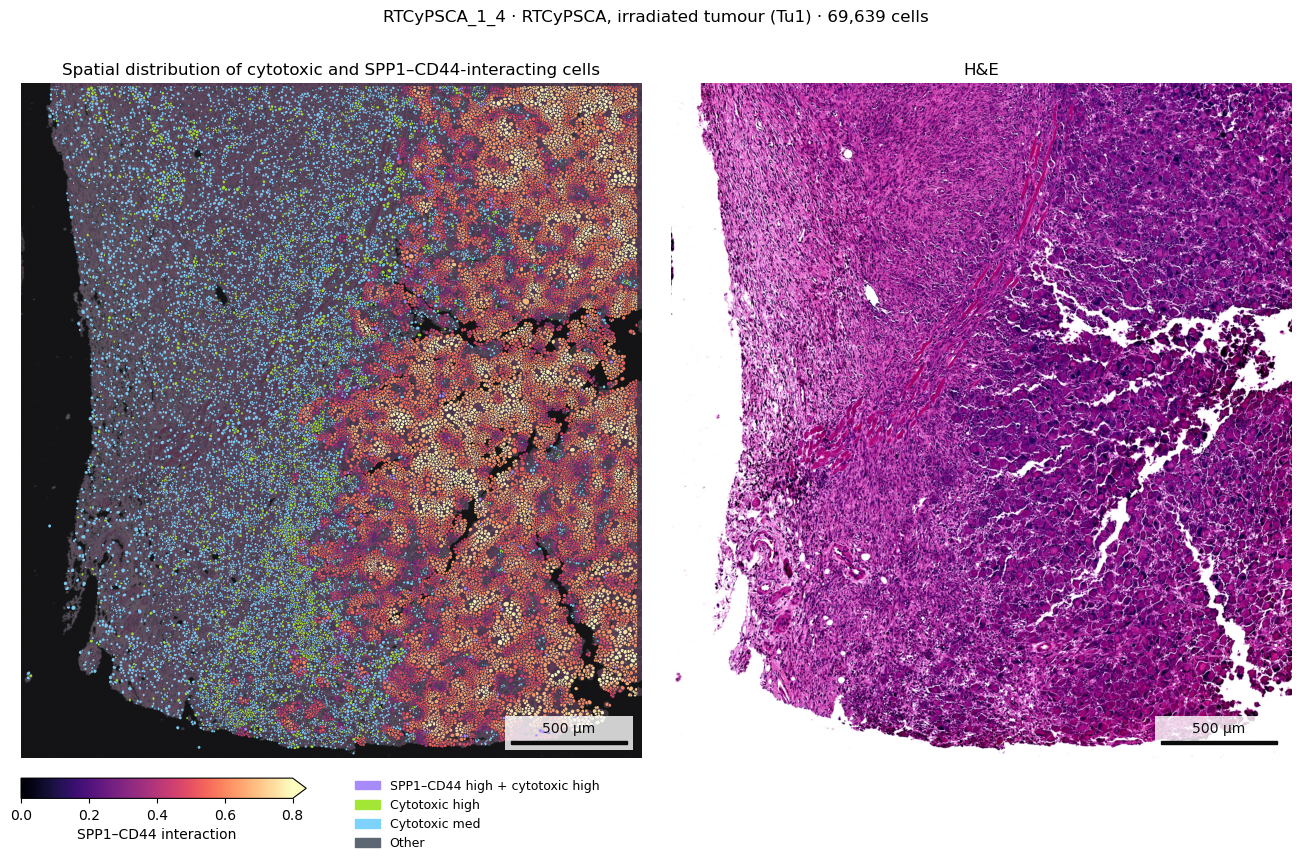

In [109]:
STYLE = {  # category: (fill, alpha), drawn in this order; INT_HIGH is filled by its score in magma
    "OTHER": (COL_OTHER, ALPHA_OTHER), "CYTO_MED": (COL_CYTO_MED, 0.95), "CYTO_HIGH": (COL_CYTO_HIGH, 0.96),
    "INT_HIGH": (None, 0.96), "BOTH": (COL_BOTH, 0.98)}
LEGEND = ([Patch(color=COL_BOTH, label="SPP1–CD44 high + cytotoxic high"),
           Patch(color=COL_CYTO_HIGH, label="Cytotoxic high")]
          + ([Patch(color=COL_CYTO_MED, label="Cytotoxic med")] if SHOW_MED else [])
          + [Patch(color=COL_OTHER, label="Other")])

fig3, (axL, axR) = panel_fig(2, panel_w=6.2, top=0.85, bottom=1.25)
show_he(axL, dark=True)
cat = gdf_sel["category"] if SHOW_MED else gdf_sel["category"].replace("CYTO_MED", "OTHER")
for z, (name, (fill, alpha)) in enumerate(STYLE.items(), start=1):
    sub = gdf_sel[cat == name]
    if not sub.empty:
        sub.plot(ax=axL, color=magma_colors(sub) if fill is None else fill, edgecolor="none",
                 alpha=alpha, zorder=z, rasterized=True)
show_he(axR, dark=False)
int_colorbar(fig3, axL, [0.0, -0.06, 0.46, 0.03], label="SPP1–CD44 interaction")
axL.legend(handles=LEGEND, loc="upper left", bbox_to_anchor=(0.52, -0.015), ncol=1, frameon=False, fontsize=9)
axL.set_title("Spatial distribution of cytotoxic and SPP1–CD44-interacting cells")
axR.set_title("H&E")
fig3.suptitle(TITLE, y=1 - 0.12 / fig3.get_figheight(), va="top")
stem3 = save(fig3, f"{TISSUE}__GranzymeScore_vs_SPP1-CD44_wholeSection")
plt.show()

## 7. Numbers for the figure description

Which cell types make up the SPP1–CD44 hotspots compared with the section as a whole, plus a summary
block. Cell types are `c2l_consolidated`, where ~32% of cells are `Unknown` dataset-wide.

In [110]:
ct = adata.obs[CELL_TYPE_COL].astype(str)
comp = pd.DataFrame({"n_hotspot": ct[lr_hot].value_counts(),
                     "pct_of_hotspots": 100 * ct[lr_hot].value_counts(normalize=True),
                     "pct_of_section": 100 * ct.value_counts(normalize=True)}).fillna(0)
comp["log2_enrichment"] = np.log2(comp["pct_of_hotspots"] / comp["pct_of_section"]).replace(-np.inf, np.nan)
comp = comp.sort_values("pct_of_hotspots", ascending=False)
comp["n_hotspot"] = comp["n_hotspot"].astype(int)
comp.to_csv(FIG_DIR / f"{TISSUE}__SPP1-CD44_hotspot_composition.csv")

per_cell = adata.obs[["cell_id", "tissue", "condition", "tumor_loc", CELL_TYPE_COL, "lr_score", "lr_pval",
                      "lr_cat", "lr_GiZ", "lr_qval", "lr_hotspot", SCORE_COL, "cytotoxic_high", "gz_GiZ",
                      "gz_qval", "gz_hotspot", "hotspot", "category"]].copy()
per_cell[["x_um", "y_um"]] = adata.obsm["spatial_um"]
per_cell.to_parquet(FIG_DIR / f"{TISSUE}__SPP1-CD44_local_scores.parquet")

top = comp[comp["pct_of_hotspots"] >= 1].head(8)
comp_lines = "\n".join(f"    {i:<18s} {r.pct_of_hotspots:5.1f}% of hotspots vs {r.pct_of_section:5.1f}% of section"
                       f"  (log2 {r.log2_enrichment:+.2f})" for i, r in top.iterrows())
n_cat = adata.obs["category"].value_counts()
print(f'''
==================== SUMMARY — report these back ====================
Section     : {TISSUE} — {CONDITION}, {SITE}; {adata.n_obs:,} cells; {SECTION_MM[0]:.1f} x {SECTION_MM[1]:.1f} mm
Expression  : {LIGAND} detected in {100 * GLOBAL['ligand_props']:.1f}% of cells, {RECEPTOR} in {100 * GLOBAL['receptor_props']:.1f}%
SPP1-CD44   : LIANA local cosine over {LR_MAX_NEIGHBOURS} neighbours (~{NEIGH_R_UM:.0f} um radius); magma fixed {INT_VMIN}-{INT_VMAX}
              median {s.median():.2f} (IQR {s.quantile(.25):.2f}-{s.quantile(.75):.2f}); {100 * (s == 0).mean():.0f}% of cells exactly 0
              global bivariate Moran's R = {GLOBAL['morans']:.3f}, p {fmt_p(GLOBAL['morans_pvals'])} ({LR_N_PERMS} permutations)
Cytotoxic   : granzyme score >= {T_CYTO_HIGH} (fixed across sections): {N_HI:,} cells ({100 * N_HI / adata.n_obs:.1f}%);
              SPP1-CD44 score under them: median {LR_UNDER_HI:.2f} vs {s.median():.2f} for all cells
Categories  : INT_HIGH >= p{PCT_INT * 100:.0f} ({thr_int:.2f}){' & both high' if BOTH_HIGH_ONLY else ''} n={n_cat.get('INT_HIGH', 0):,} | BOTH n={n_cat.get('BOTH', 0):,}
              cytotoxic high n={n_cat.get('CYTO_HIGH', 0):,} | med (>= {T_CYTO_MED}) n={n_cat.get('CYTO_MED', 0):,} | OTHER n={n_cat.get('OTHER', 0):,}
              cytotoxic high is {HI_IN_INT:.1f}% of INT_HIGH cells vs {HI_ELSEWHERE:.1f}% elsewhere;
              BOTH = {N_BOTH:,} cells, {N_BOTH / max(EXP_BOTH, 1e-9):.2f}x the {EXP_BOTH:,.0f} expected if independent
Hotspots    : Gi* (binary kNN incl. self), BH q < {HOT_FDR}
              SPP1-CD44 {int(lr_hot.sum()):,} cells ({100 * lr_hot.mean():.1f}%) — k={LR_K_GI}, on the score where both genes are high nearby
              granzyme {int(gz_hot.sum()):,} cells ({100 * gz_hot.mean():.1f}%) — k={GZ_K_GI}, on the module score
              in both {N_HOT_BOTH:,} cells = {N_HOT_BOTH / max(EXP_HOT_BOTH, 1e-9):.2f}x the {EXP_HOT_BOTH:,.0f} expected if independent;
              outside the SPP1-CD44 hotspots, granzyme-hotspot cells sit a median {D_GZ[1]:.0f} um (IQR {D_GZ[0]:.0f}-{D_GZ[2]:.0f})
              from the nearest one, vs {D_OUT:.0f} um for all cells there
Hotspot composition (c2l_consolidated):
{comp_lines}
Scale       : {UM_PER_PX} um per full-res px ({UM_PER_IMG_PX:.3f} um per H&E px); the scale bar depends on this constant
Files       : {FIG_DIR}
              {stem1}, {stem2}, {stem3} (.png/.pdf, and __slide.png for PowerPoint),
              *_hotspot_composition.csv, *_local_scores.parquet

WORDING THE DATA SUPPORTS
  "local Spp1–Cd44 co-expression" — not binding, and not direction (who signals to whom).
  Spatial Spp1 counts carry spillover, and single cell puts most Spp1 in tumour cells (spp1Analysis 01c),
  so describe it as a tumour-driven Spp1->Cd44 axis.
=====================================================================
''')


==================== SUMMARY — report these back ====================
Section     : RTCyPSCA_1_4 — RTCyPSCA, irradiated tumour (Tu1); 69,639 cells; 2.6 x 2.9 mm
Expression  : Spp1 detected in 49.1% of cells, Cd44 in 17.5%
SPP1-CD44   : LIANA local cosine over 30 neighbours (~29 um radius); magma fixed 0.0-0.8
              median 0.31 (IQR 0.00-0.53); 38% of cells exactly 0
              global bivariate Moran's R = 0.240, p < 0.01 (100 permutations)
Cytotoxic   : granzyme score >= 0.575 (fixed across sections): 3,485 cells (5.0%);
              SPP1-CD44 score under them: median 0.19 vs 0.31 for all cells
Categories  : INT_HIGH >= p45 (0.25) & both high n=25,353 | BOTH n=548
              cytotoxic high n=2,937 | med (>= 0.16) n=13,187 | OTHER n=27,614
              cytotoxic high is 2.1% of INT_HIGH cells vs 6.7% elsewhere;
              BOTH = 548 cells, 0.42x the 1,296 expected if independent
Hotspots    : Gi* (binary kNN incl. self), BH q < 0.05
              SPP1-CD44 21,304 cel